In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy


plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 25
})

In [2]:
#Function Definitions
def partial_x_2d(f,dx):
    """Compute ∂f/∂x using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dx = np.zeros_like(f)
    
    # Central difference in x-direction (axis=0)
    df_dx[1:Nx-1, :] = (f[2:Nx, :] - f[0:Nx-2, :]) / (2 * dx)
    
    # Periodic boundaries (x-direction)
    df_dx[0, :] = (f[1, :] - f[-1, :]) / (2 * dx)
    df_dx[-1, :] = (f[0, :] - f[-2, :]) / (2 * dx)
    
    return df_dx

def partial_y_2d(f,dy):
    """Compute ∂f/∂y using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dy = np.zeros_like(f)
    
    # Central difference in y-direction (axis=1)
    df_dy[:, 1:Ny-1] = (f[:, 2:Ny] - f[:, 0:Ny-2]) / (2 * dy)
    
    # Periodic boundaries (y-direction)
    df_dy[:, 0] = (f[:, 1] - f[:, -1]) / (2 * dy)
    df_dy[:, -1] = (f[:, 0] - f[:, -2]) / (2 * dy)
    
    return df_dy

def partial_x_fft(f, dx):
    """
    Calculate ∂f/∂x using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dx (float): Grid spacing in the x-direction.

    Returns:
        df_dx (2D np.array): Partial derivative ∂f/∂x.
    """
    nx, ny = f.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi  # Wavenumbers in x
    kx = kx[:, np.newaxis]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dx_hat = 1j * kx * f_hat
    df_dx = np.fft.ifft2(df_dx_hat).real

    return np.array(df_dx)

def partial_y_fft(f, dy):
    """
    Calculate ∂f/∂y using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dy (float): Grid spacing in the y-direction.

    Returns:
        df_dy (2D np.array): Partial derivative ∂f/∂y.
    """
    nx, ny = f.shape
    ky = np.fft.fftfreq(ny, d=dy) * 2 * np.pi  # Wavenumbers in y
    ky = ky[np.newaxis, :]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dy_hat = 1j * ky * f_hat
    df_dy = np.fft.ifft2(df_dy_hat).real

    return df_dy

def index_of_just_smaller(arr, value):
    arr = np.asarray(arr)
    mask = arr < value
    if not np.any(mask):
        return None  # No smaller value exists
    return np.argmax(np.where(mask, arr, -np.inf))


def iterative_filtering1D(field, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=Xi)
    fif.run(field)
    print(fif.IMC.shape)
    filtered_signal = np.sum(fif.IMC[index:],axis=0)
    return filtered_signal

dx = 0.0625
dy = 0.0625

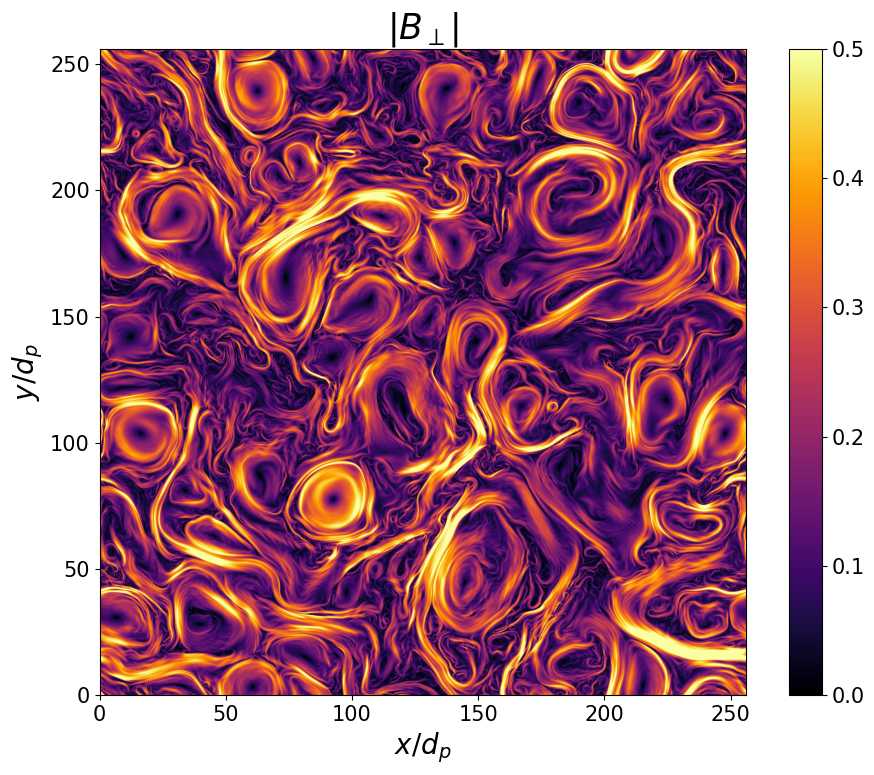

In [4]:
#Lets Plot J_Parallel

File_Bx = '/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/Bx_ApJ_t200.h5'
File_By = '/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/By_ApJ_t200.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

#Compute J_parallel using Fourier Transform
B_perp = np.sqrt(data_Bx**2 + data_By**2)

Nx, Ny = B_perp.shape

Lx = Nx * dx
Ly = Ny * dy

dx = dy = 0.0625

Nx, Ny = B_perp.shape

extent = [0, Nx*dx, 0, Ny*dy]

plt.figure(figsize=(10, 8))

img = plt.imshow(
    B_perp,
    cmap='inferno',
    vmin=0,
    vmax=0.5,
    extent=extent
)

plt.colorbar(img)

plt.title(r'$|B_\perp|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig('Bperp_200.png', dpi=300)
plt.show()

orientation fixed via div B (rms 8.75e-02 vs 2.73e-01)
window 32 d_p = 512 cells -> 1536 px; computing LIC ...
saved Jpar_LIC_t200_art.png (1536 x 1536 px) and Jpar_LIC_t200_check.png in 30 s


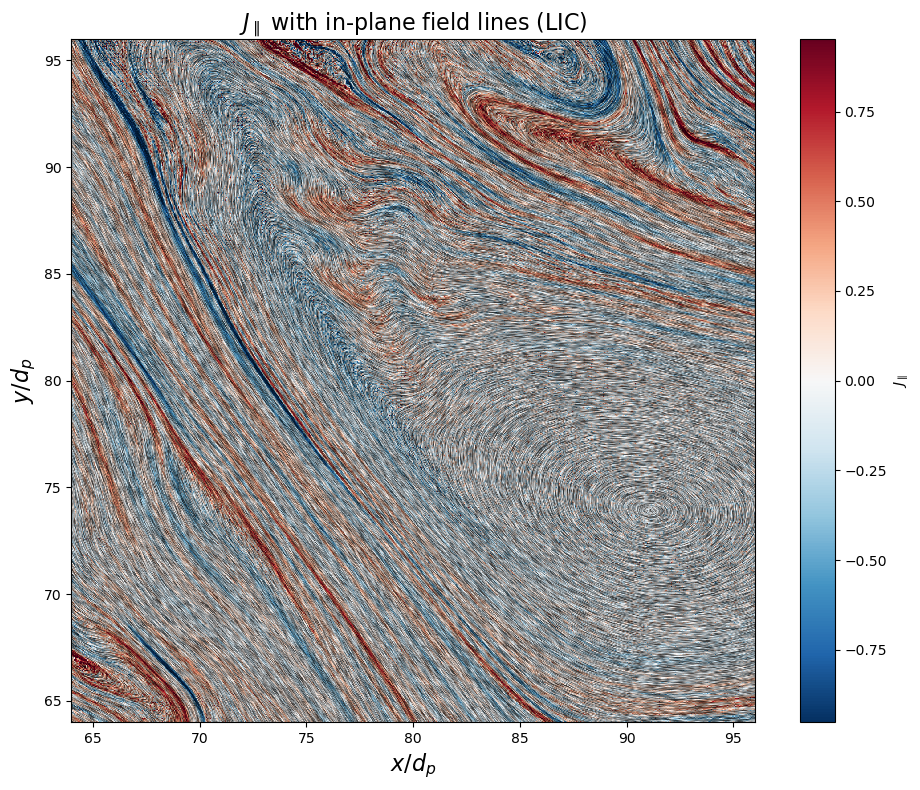

In [1]:
"""
LIC (line integral convolution) image of the in-plane magnetic field lines,
coloured by J_parallel (or J_z).

Field lines come from Bx, By only. If FILE_BZ is given the colour is the true
J_parallel = J.B/|B|; otherwise J_z = dBy/dx - dBx/dy is used (with B0 out of
plane, J_parallel ~ J_z anyway).

Outputs
  <OUT>_art.png      full-bleed image, no axes, 300 dpi metadata (competition)
  <OUT>_check.png    same image with axes and colourbar (for checking)
"""
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from scipy.ndimage import map_coordinates

# ------------------------------------------------------------------ settings
RUN = "/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_1/beta_e_1/"
FILE_BX = RUN + "Bx_ApJ_t200.h5"
FILE_BY = RUN + "By_ApJ_t200.h5"
FILE_BZ = RUN + "Bz_ApJ_t200.h5"   # set to None to colour by J_z instead
dx = 0.0625                          # cell size [d_p]

# region to draw (in d_p); the full box is 256 x 256 d_p
X0, Y0 = 64.0, 64.0                  # lower-left corner
SIZE = 32.0                          # side length; 64 d_p = 1024 cells

OVERSAMPLE = 3        # output pixels per cell: 1024 cells -> 3072 px (~10 in at 300 dpi)
LENGTH = 30           # streak half-length in output pixels (longer = smoother lines)
STEP = 0.5            # integration step in output pixels
CMAP = "RdBu_r"       # diverging; try "berlin" (dark centre, matplotlib >= 3.10)
CLIP_PCT = 99.5       # colour range = this percentile of |J|
TEXTURE = 0.75        # 0 = flat colour, 1 = strongest field-line texture
OUT = "Jpar_LIC_t200"
SEED = 1
# ------------------------------------------------------------------------------


def deriv(f, d, axis):
    n = f.shape[axis]
    k = 2 * np.pi * np.fft.fftfreq(n, d=d)
    shape = [1] * f.ndim
    shape[axis] = n
    return np.real(np.fft.ifft(1j * k.reshape(shape) * np.fft.fft(f, axis=axis), axis=axis))


def read(fn):
    with h5py.File(fn, "r") as f:
        return f["DS1"][:].T.astype(np.float64)


def sample(arr, r, c, mode):
    try:
        return map_coordinates(arr, [r, c], order=1, mode=mode)
    except RuntimeError:  # older scipy without 'grid-wrap'
        return map_coordinates(arr, [r, c], order=1, mode="wrap")


def lic(ux, uy, row0, col0, n_cells, f, length, step, seed):
    """LIC texture for a square window of the periodic unit-vector field (ux, uy).

    ux, uy : field direction along columns (x) and rows (y) of the full arrays
    row0, col0, n_cells : window position and size in cells
    f : output pixels per cell
    """
    npx = n_cells * f
    margin = int(np.ceil(length * step)) + 2
    rng = np.random.default_rng(seed)
    noise = rng.random((npx + 2 * margin, npx + 2 * margin))

    R0, C0 = np.mgrid[0:npx, 0:npx].astype(np.float64)
    acc = noise[margin:-margin, margin:-margin].copy()
    wsum = np.ones_like(acc)
    for sign in (1.0, -1.0):
        R, C = R0.copy(), C0.copy()
        for k in range(1, length + 1):
            # RK2 (midpoint) step along the field line, in output pixels
            fr, fc = row0 + R / f, col0 + C / f
            vy1, vx1 = sample(uy, fr, fc, "grid-wrap"), sample(ux, fr, fc, "grid-wrap")
            fr, fc = row0 + (R + 0.5 * sign * step * vy1) / f, col0 + (C + 0.5 * sign * step * vx1) / f
            vy2, vx2 = sample(uy, fr, fc, "grid-wrap"), sample(ux, fr, fc, "grid-wrap")
            R += sign * step * vy2
            C += sign * step * vx2
            w = 0.5 * (1 + np.cos(np.pi * k / (length + 1)))  # Hann weight
            acc += w * sample(noise, R + margin, C + margin, "nearest")
            wsum += w
    return acc / wsum


def main():
    t_start = time.time()
    bx, by = read(FILE_BX), read(FILE_BY)
    bz = read(FILE_BZ) if FILE_BZ else None

    # put x along columns and y along rows (decided by div B = 0)
    div_a = np.std(deriv(bx, dx, 0) + deriv(by, dx, 1))
    div_b = np.std(deriv(bx, dx, 1) + deriv(by, dx, 0))
    if div_a < div_b:  # x is currently along rows -> transpose
        bx, by = bx.T, by.T
        bz = bz.T if bz is not None else None
    print(f"orientation fixed via div B (rms {min(div_a, div_b):.2e} vs {max(div_a, div_b):.2e})")

    # colour quantity
    jz = deriv(by, dx, 1) - deriv(bx, dx, 0)
    if bz is not None:
        jx, jy = deriv(bz, dx, 0), -deriv(bz, dx, 1)
        bmag = np.sqrt(bx ** 2 + by ** 2 + bz ** 2)
        J = (jx * bx + jy * by + jz * bz) / bmag
        label = r"$J_\parallel$"
        del jx, jy, bmag
    else:
        J = jz
        label = r"$J_z$"

    # in-plane field direction
    bperp = np.hypot(bx, by) + 1e-30
    ux, uy = bx / bperp, by / bperp

    n = int(round(SIZE / dx))
    row0, col0 = int(round(Y0 / dx)), int(round(X0 / dx))
    print(f"window {SIZE:g} d_p = {n} cells -> {n * OVERSAMPLE} px; computing LIC ...", flush=True)
    tex = lic(ux, uy, row0, col0, n, OVERSAMPLE, LENGTH, STEP, SEED)

    # contrast-stretch the texture to [0, 1]
    lo, hi = np.percentile(tex, [1, 99])
    tex = np.clip((tex - lo) / (hi - lo), 0, 1)

    # colour on the output grid
    npx = n * OVERSAMPLE
    R, C = np.mgrid[0:npx, 0:npx].astype(np.float64)
    Jw = sample(J, row0 + (R + 0.5) / OVERSAMPLE - 0.5, col0 + (C + 0.5) / OVERSAMPLE - 0.5, "grid-wrap")
    vmax = np.percentile(np.abs(Jw), CLIP_PCT)
    norm = Normalize(-vmax, vmax)
    rgb = plt.get_cmap(CMAP)(norm(Jw))[..., :3]
    shade = (1 - TEXTURE) + TEXTURE * tex
    img = np.clip(rgb * shade[..., None], 0, 1)

    plt.imsave(f"{OUT}_art.png", img, origin="lower", dpi=300)

    extent = [X0, X0 + SIZE, Y0, Y0 + SIZE]
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(img, origin="lower", extent=extent, interpolation="none")
    sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
    fig.colorbar(sm, ax=ax, label=label)
    ax.set_xlabel(r"$x/d_p$", fontsize=16)
    ax.set_ylabel(r"$y/d_p$", fontsize=16)
    ax.set_title(f"{label} with in-plane field lines (LIC)", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"{OUT}_check.png", dpi=200)
    print(f"saved {OUT}_art.png ({npx} x {npx} px) and {OUT}_check.png "
          f"in {time.time() - t_start:.0f} s")


if __name__ == "__main__":
    main()

In [ ]:
#Lets Plot J_Parallel

File_Bx = '/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/Bx_ApJ_t200.h5'
File_By = '/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/By_ApJ_t200.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

#Compute J_parallel using Fourier Transform
B_perp = np.sqrt(data_Bx**2 + data_By**2)

Nx, Ny = B_perp.shape

Lx = Nx * dx
Ly = Ny * dy

dx = dy = 0.0625

Nx, Ny = B_perp.shape

extent = [0, Nx*dx, 0, Ny*dy]

plt.figure(figsize=(10, 8))

img = plt.imshow(
    B_perp,
    cmap='inferno',
    vmin=0,
    vmax=0.5,
    extent=extent
)

plt.colorbar(img)

plt.title(r'$|B_\perp|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig('Bperp_200.png', dpi=300)
plt.show()

21 times: t = 0 .. 200
grid 4096 x 4096; x along rows (transposing)
  t=   0  (1/21)       7 s elapsed, ~   132 s to go
  t= 100  (11/21)      10 s elapsed, ~     9 s to go
  t= 200  (21/21)      13 s elapsed, ~     0 s to go
saved Bperp_time_wheel_art.png (3000 px, 9.0 MB)
saved Bperp_time_wheel_check.png  (total 19 s)


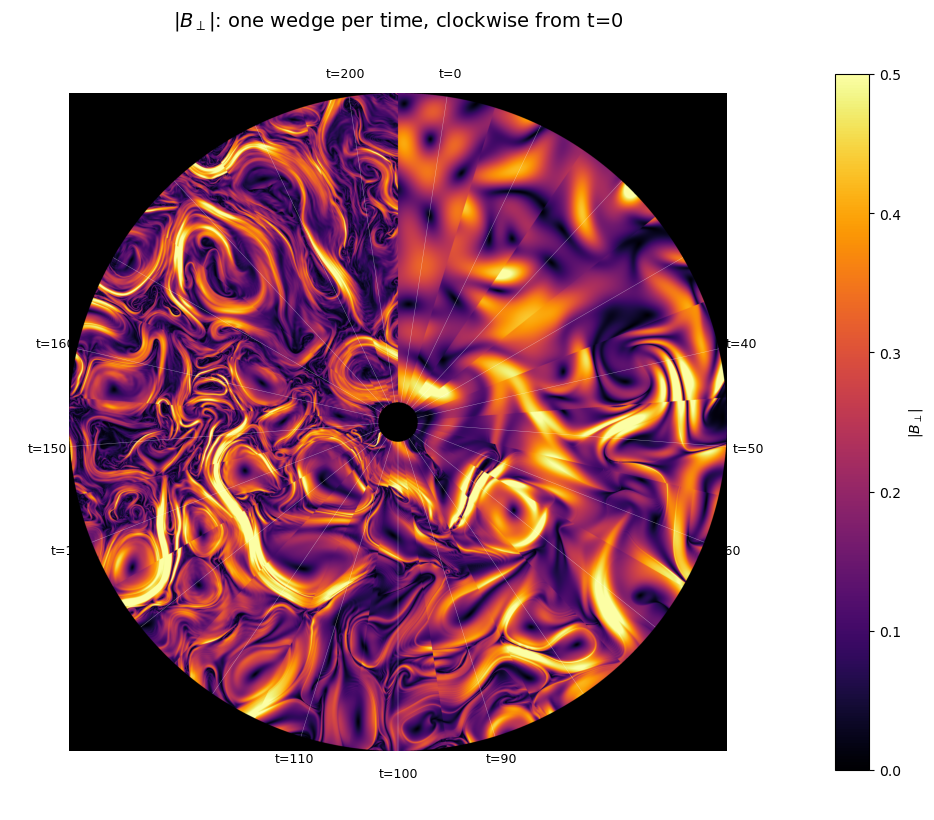

In [4]:
"""
Time wheel: a disc cut into N wedges (one per output time). Each wedge shows the
field at that time, at its own position in the box, so going round the circle
(clockwise from 12 o'clock) the plasma evolves from the first to the last output.

Outputs
  <OUT>_art.png    disc only, no axes, resized to OUT_PX, 300 dpi metadata
                   (also a .jpg if the PNG is over 20 MB, the competition limit)
  <OUT>_check.png  same with a colourbar and time labels round the rim
"""
import glob
import os
import re
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from PIL import Image

# ------------------------------------------------------------------ settings
RUN = "/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/"
QUANTITY = "Bperp"          # "Bperp" = |B_perp|, or "Jz" = dBy/dx - dBx/dy
T_FIRST, T_LAST = 0, 200    # times to use (only files that exist are used)
T_STEP = 10                  # use every T_STEP-th time (e.g. 5 -> 60 wider wedges)
dx = 0.0625                 # cell size [d_p]

CENTER = None               # (x, y) of the disc centre in d_p; None = box centre
RADIUS = 128.0              # disc radius in d_p (128 = largest circle in the box)
R_INNER = 0.06              # fraction of RADIUS left empty at the hub

CMAP = "inferno"            # e.g. "RdBu_r" or "berlin" for Jz
VMIN, VMAX = 0.0, 0.5       # colour range; None, None = automatic
BACKGROUND = "black"        # "black", "white" or "transparent"
OUT_PX = 3000               # side of the final image in pixels (10 in at 300 dpi)
OUT = "Bperp_time_wheel"
# ------------------------------------------------------------------------------


def deriv(f, d, axis):
    n = f.shape[axis]
    k = 2 * np.pi * np.fft.fftfreq(n, d=d)
    shape = [1] * f.ndim
    shape[axis] = n
    return np.real(np.fft.ifft(1j * k.reshape(shape) * np.fft.fft(f, axis=axis), axis=axis))


def read(tag, t):
    with h5py.File(f"{RUN}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T.astype(np.float64)


def available_times():
    times = []
    for fn in glob.glob(f"{RUN}Bx_ApJ_t*.h5"):
        m = re.search(r"_t(\d+)\.h5$", fn)
        if m and T_FIRST <= int(m.group(1)) <= T_LAST and (int(m.group(1)) - T_FIRST) % T_STEP == 0:
            t = int(m.group(1))
            if os.path.exists(f"{RUN}By_ApJ_t{t}.h5"):
                times.append(t)
    return sorted(times)


def quantity(bx, by):
    if QUANTITY == "Jz":
        return deriv(by, dx, 1) - deriv(bx, dx, 0)
    return np.hypot(bx, by)


def main():
    t0 = time.time()
    times = available_times()
    nt = len(times)
    if nt == 0:
        raise SystemExit(f"no Bx/By files between t={T_FIRST} and t={T_LAST} in {RUN}")
    print(f"{nt} times: t = {times[0]} .. {times[-1]}")

    # orientation from the first snapshot: put x along columns, y along rows
    bx, by = read("Bx", times[0]), read("By", times[0])
    div_a = np.std(deriv(bx, dx, 0) + deriv(by, dx, 1))
    div_b = np.std(deriv(bx, dx, 1) + deriv(by, dx, 0))
    transpose = div_a < div_b
    n = bx.shape[0]
    print(f"grid {n} x {n}; x along {'rows (transposing)' if transpose else 'columns'}")

    # disc geometry on the cell grid (periodic indexing if it crosses the edge)
    xc, yc = CENTER if CENTER else (n * dx / 2, n * dx / 2)
    r = int(round(RADIUS / dx))
    c0, r0 = int(round(xc / dx)) - r, int(round(yc / dx)) - r
    cols = (np.arange(c0, c0 + 2 * r)) % n
    rows = (np.arange(r0, r0 + 2 * r)) % n
    Y, X = np.mgrid[0:2 * r, 0:2 * r] + 0.5 - r          # cell centres relative to centre
    rad = np.hypot(X, Y)
    theta = np.mod(np.arctan2(X, Y), 2 * np.pi)          # clockwise from 12 o'clock
    inside = (rad <= r) & (rad >= R_INNER * r)
    wedge = np.where(inside, np.minimum((theta / (2 * np.pi) * nt).astype(int), nt - 1), -1)
    order = np.argsort(wedge.ravel(), kind="stable")
    counts = np.bincount(wedge.ravel()[wedge.ravel() >= 0], minlength=nt)
    start = np.searchsorted(wedge.ravel()[order], 0)
    groups = np.split(order[start:], np.cumsum(counts)[:-1])

    value = np.full(wedge.size, np.nan)
    for k, t in enumerate(times):
        if k > 0:
            bx, by = read("Bx", t), read("By", t)
        if transpose:
            bx, by = bx.T, by.T
        q = quantity(bx, by)[np.ix_(rows, cols)].ravel()
        value[groups[k]] = q[groups[k]]
        if k % 10 == 0 or k == nt - 1:
            el = time.time() - t0
            print(f"  t={t:4d}  ({k + 1}/{nt})  {el:6.0f} s elapsed, "
                  f"~{el / (k + 1) * (nt - k - 1):6.0f} s to go", flush=True)
    value = value.reshape(wedge.shape)

    # colours
    vmin, vmax = VMIN, VMAX
    if vmin is None or vmax is None:
        if QUANTITY == "Jz":
            vmax = np.nanpercentile(np.abs(value), 99.5)
            vmin = -vmax
        else:
            vmin, vmax = 0.0, np.nanpercentile(value, 99.5)
    norm = Normalize(vmin, vmax)
    rgba = plt.get_cmap(CMAP)(norm(np.nan_to_num(value)))
    bg = {"black": (0, 0, 0, 1), "white": (1, 1, 1, 1), "transparent": (0, 0, 0, 0)}[BACKGROUND]
    rgba[~inside] = bg

    # art version: flip rows so y points up, resize, save
    img = Image.fromarray((rgba[::-1] * 255).astype(np.uint8), "RGBA")
    if OUT_PX and OUT_PX != img.width:
        img = img.resize((OUT_PX, OUT_PX), Image.LANCZOS)
    if BACKGROUND != "transparent":
        img = img.convert("RGB")
    img.save(f"{OUT}_art.png", dpi=(300, 300))
    size_mb = os.path.getsize(f"{OUT}_art.png") / 1e6
    print(f"saved {OUT}_art.png ({img.width} px, {size_mb:.1f} MB)")
    if size_mb > 20:
        img.convert("RGB").save(f"{OUT}_art.jpg", quality=95, dpi=(300, 300))
        print(f"PNG is over 20 MB: also saved {OUT}_art.jpg "
              f"({os.path.getsize(f'{OUT}_art.jpg') / 1e6:.1f} MB)")

    # check version with colourbar and time labels
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.imshow(rgba, origin="lower", extent=[-RADIUS, RADIUS, -RADIUS, RADIUS])
    step = max(1, nt // 12)
    for k in range(0, nt, step):
        a = (k + 0.5) / nt * 2 * np.pi
        ax.text(1.07 * RADIUS * np.sin(a), 1.07 * RADIUS * np.cos(a), f"t={times[k]}",
                ha="center", va="center", fontsize=9)
        ax.plot([R_INNER * RADIUS * np.sin(a), RADIUS * np.sin(a)],
                [R_INNER * RADIUS * np.cos(a), RADIUS * np.cos(a)], color="w", lw=0.3, alpha=0.5)
    ax.set_xlim(-1.18 * RADIUS, 1.18 * RADIUS)
    ax.set_ylim(-1.18 * RADIUS, 1.18 * RADIUS)
    ax.set_aspect("equal")
    ax.axis("off")
    label = r"$|B_\perp|$" if QUANTITY == "Bperp" else r"$J_z$"
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP), ax=ax, shrink=0.8, label=label)
    ax.set_title(f"{label}: one wedge per time, clockwise from t={times[0]}", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"{OUT}_check.png", dpi=150)
    print(f"saved {OUT}_check.png  (total {time.time() - t0:.0f} s)")


if __name__ == "__main__":
    main()

100 times: t = 1 .. 100
grid 4096 x 4096; x along rows (transposing)
  t=   1  (1/100)       5 s elapsed, ~   513 s to go
  t=  11  (11/100)       9 s elapsed, ~    70 s to go
  t=  21  (21/100)      12 s elapsed, ~    44 s to go
  t=  31  (31/100)      14 s elapsed, ~    32 s to go
  t=  41  (41/100)      17 s elapsed, ~    24 s to go
  t=  51  (51/100)      20 s elapsed, ~    19 s to go
  t=  61  (61/100)      23 s elapsed, ~    14 s to go
  t=  71  (71/100)      25 s elapsed, ~    10 s to go
  t=  81  (81/100)      28 s elapsed, ~     7 s to go
  t=  91  (91/100)      31 s elapsed, ~     3 s to go
  t= 100  (100/100)      34 s elapsed, ~     0 s to go
saved Bperp_time_wheel_art.png (3000 px, 9.1 MB)
saved Bperp_time_wheel_check.png  (total 39 s)


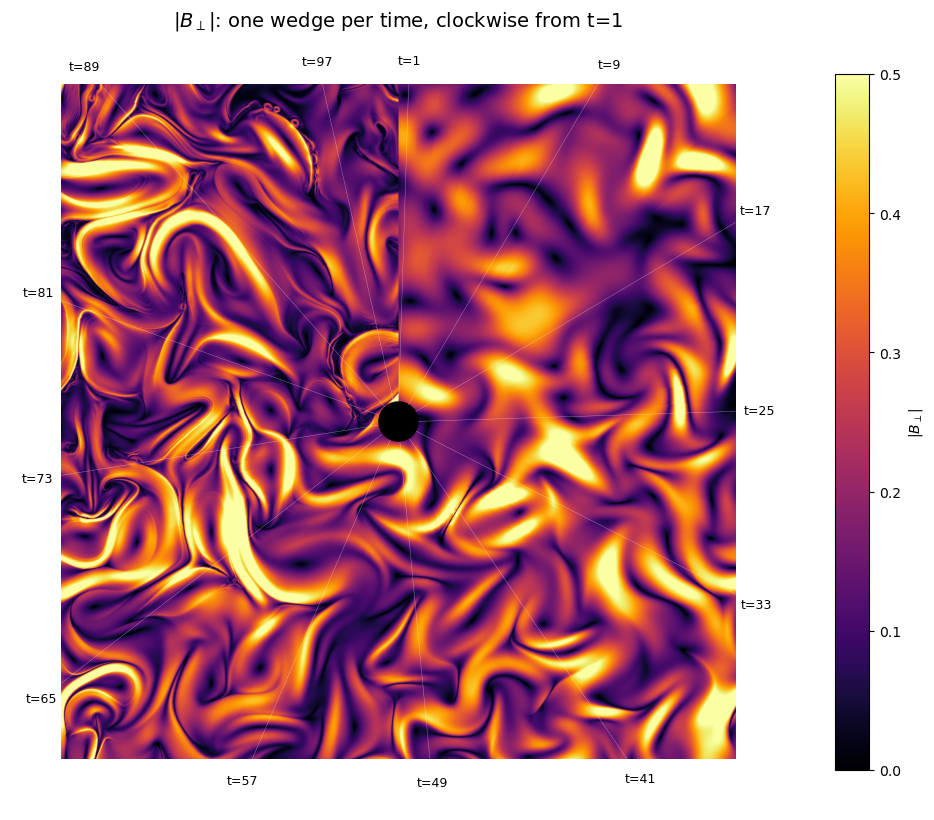

In [7]:
"""
Time wheel: an image cut into N wedges (one per output time) radiating from the
centre. Each wedge shows the field at that time, at its own position in the box,
so going round (clockwise from 12 o'clock) the plasma evolves from the first to
the last output. SHAPE = "square" fills the whole square (wedges run out to the
edges and corners); SHAPE = "disc" cuts it to the inscribed circle.

Outputs
  <OUT>_art.png    image only, no axes, resized to OUT_PX, 300 dpi metadata
                   (also a .jpg if the PNG is over 20 MB, the competition limit)
  <OUT>_check.png  same with a colourbar and time labels round the rim
"""
import glob
import os
import re
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from PIL import Image

# ------------------------------------------------------------------ settings
RUN = "/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/"
QUANTITY = "Bperp"          # "Bperp" = |B_perp|, or "Jz" = dBy/dx - dBx/dy
T_FIRST, T_LAST = 1, 100    # times to use (only files that exist are used)
T_STEP = 1                  # use every T_STEP-th time (e.g. 5 -> 60 wider wedges)
dx = 0.0625                 # cell size [d_p]

SHAPE = "square"            # "square" = fill the whole square, "disc" = inscribed circle
CENTER = None               # (x, y) of the centre in d_p; None = box centre
RADIUS = 128.0              # half-width of the square (or disc radius) in d_p; 128 = whole box
R_INNER = 0.06              # fraction of RADIUS left empty at the hub (0 = none)

CMAP = "inferno"            # e.g. "RdBu_r" or "berlin" for Jz
VMIN, VMAX = 0.0, 0.5       # colour range; None, None = automatic
BACKGROUND = "black"        # "black", "white" or "transparent"
OUT_PX = 3000               # side of the final image in pixels (10 in at 300 dpi)
OUT = "Bperp_time_wheel"
# ------------------------------------------------------------------------------


def deriv(f, d, axis):
    n = f.shape[axis]
    k = 2 * np.pi * np.fft.fftfreq(n, d=d)
    shape = [1] * f.ndim
    shape[axis] = n
    return np.real(np.fft.ifft(1j * k.reshape(shape) * np.fft.fft(f, axis=axis), axis=axis))


def read(tag, t):
    with h5py.File(f"{RUN}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T.astype(np.float64)


def available_times():
    times = []
    for fn in glob.glob(f"{RUN}Bx_ApJ_t*.h5"):
        m = re.search(r"_t(\d+)\.h5$", fn)
        if m and T_FIRST <= int(m.group(1)) <= T_LAST and (int(m.group(1)) - T_FIRST) % T_STEP == 0:
            t = int(m.group(1))
            if os.path.exists(f"{RUN}By_ApJ_t{t}.h5"):
                times.append(t)
    return sorted(times)


def quantity(bx, by):
    if QUANTITY == "Jz":
        return deriv(by, dx, 1) - deriv(bx, dx, 0)
    return np.hypot(bx, by)


def main():
    t0 = time.time()
    times = available_times()
    nt = len(times)
    if nt == 0:
        raise SystemExit(f"no Bx/By files between t={T_FIRST} and t={T_LAST} in {RUN}")
    print(f"{nt} times: t = {times[0]} .. {times[-1]}")

    # orientation from the first snapshot: put x along columns, y along rows
    bx, by = read("Bx", times[0]), read("By", times[0])
    div_a = np.std(deriv(bx, dx, 0) + deriv(by, dx, 1))
    div_b = np.std(deriv(bx, dx, 1) + deriv(by, dx, 0))
    transpose = div_a < div_b
    n = bx.shape[0]
    print(f"grid {n} x {n}; x along {'rows (transposing)' if transpose else 'columns'}")

    # disc geometry on the cell grid (periodic indexing if it crosses the edge)
    xc, yc = CENTER if CENTER else (n * dx / 2, n * dx / 2)
    r = int(round(RADIUS / dx))
    c0, r0 = int(round(xc / dx)) - r, int(round(yc / dx)) - r
    cols = (np.arange(c0, c0 + 2 * r)) % n
    rows = (np.arange(r0, r0 + 2 * r)) % n
    Y, X = np.mgrid[0:2 * r, 0:2 * r] + 0.5 - r          # cell centres relative to centre
    rad = np.hypot(X, Y)
    theta = np.mod(np.arctan2(X, Y), 2 * np.pi)          # clockwise from 12 o'clock
    inside = rad >= R_INNER * r
    if SHAPE == "disc":
        inside &= rad <= r
    wedge = np.where(inside, np.minimum((theta / (2 * np.pi) * nt).astype(int), nt - 1), -1)
    order = np.argsort(wedge.ravel(), kind="stable")
    counts = np.bincount(wedge.ravel()[wedge.ravel() >= 0], minlength=nt)
    start = np.searchsorted(wedge.ravel()[order], 0)
    groups = np.split(order[start:], np.cumsum(counts)[:-1])

    value = np.full(wedge.size, np.nan)
    for k, t in enumerate(times):
        if k > 0:
            bx, by = read("Bx", t), read("By", t)
        if transpose:
            bx, by = bx.T, by.T
        q = quantity(bx, by)[np.ix_(rows, cols)].ravel()
        value[groups[k]] = q[groups[k]]
        if k % 10 == 0 or k == nt - 1:
            el = time.time() - t0
            print(f"  t={t:4d}  ({k + 1}/{nt})  {el:6.0f} s elapsed, "
                  f"~{el / (k + 1) * (nt - k - 1):6.0f} s to go", flush=True)
    value = value.reshape(wedge.shape)

    # colours
    vmin, vmax = VMIN, VMAX
    if vmin is None or vmax is None:
        if QUANTITY == "Jz":
            vmax = np.nanpercentile(np.abs(value), 99.5)
            vmin = -vmax
        else:
            vmin, vmax = 0.0, np.nanpercentile(value, 99.5)
    norm = Normalize(vmin, vmax)
    rgba = plt.get_cmap(CMAP)(norm(np.nan_to_num(value)))
    bg = {"black": (0, 0, 0, 1), "white": (1, 1, 1, 1), "transparent": (0, 0, 0, 0)}[BACKGROUND]
    rgba[~inside] = bg

    # art version: flip rows so y points up, resize, save
    img = Image.fromarray((rgba[::-1] * 255).astype(np.uint8), "RGBA")
    if OUT_PX and OUT_PX != img.width:
        img = img.resize((OUT_PX, OUT_PX), Image.LANCZOS)
    if BACKGROUND != "transparent":
        img = img.convert("RGB")
    img.save(f"{OUT}_art.png", dpi=(300, 300))
    size_mb = os.path.getsize(f"{OUT}_art.png") / 1e6
    print(f"saved {OUT}_art.png ({img.width} px, {size_mb:.1f} MB)")
    if size_mb > 20:
        img.convert("RGB").save(f"{OUT}_art.jpg", quality=95, dpi=(300, 300))
        print(f"PNG is over 20 MB: also saved {OUT}_art.jpg "
              f"({os.path.getsize(f'{OUT}_art.jpg') / 1e6:.1f} MB)")

    # check version with colourbar and time labels
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.imshow(rgba, origin="lower", extent=[-RADIUS, RADIUS, -RADIUS, RADIUS])
    step = max(1, nt // 12)
    for k in range(0, nt, step):
        a = (k + 0.5) / nt * 2 * np.pi
        edge = RADIUS if SHAPE == "disc" else RADIUS / max(abs(np.sin(a)), abs(np.cos(a)))
        ax.text((edge + 0.07 * RADIUS) * np.sin(a), (edge + 0.07 * RADIUS) * np.cos(a),
                f"t={times[k]}", ha="center", va="center", fontsize=9)
        ax.plot([R_INNER * RADIUS * np.sin(a), edge * np.sin(a)],
                [R_INNER * RADIUS * np.cos(a), edge * np.cos(a)], color="w", lw=0.3, alpha=0.5)
    lim = 1.18 * RADIUS if SHAPE == "disc" else 1.15 * RADIUS
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.axis("off")
    label = r"$|B_\perp|$" if QUANTITY == "Bperp" else r"$J_z$"
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP), ax=ax, shrink=0.8, label=label)
    ax.set_title(f"{label}: one wedge per time, clockwise from t={times[0]}", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"{OUT}_check.png", dpi=150)
    print(f"saved {OUT}_check.png  (total {time.time() - t0:.0f} s)")


if __name__ == "__main__":
    main()

x along rows -> transposing
t=200: |B_perp| 99.5th pct = 0.59, |J_z| 99.5th pct = 1.61
  saved gallery_bp0.0625/scaling_comparison.png
  saved gallery_bp0.0625/3_relief_Jz.png
  saved gallery_bp0.0625/3_relief_Bperp.png
60 times (t = 1 .. 296, step 5); reading ...
  t=   1 (1/60)     26 s, ~ 1521 s to go
  t=  51 (11/60)     51 s, ~  225 s to go
  t= 101 (21/60)     74 s, ~  137 s to go
  t= 151 (31/60)    105 s, ~   98 s to go
  t= 201 (41/60)    131 s, ~   61 s to go
  t= 251 (51/60)    153 s, ~   27 s to go
  t= 296 (60/60)    178 s, ~    0 s to go
  saved gallery_bp0.0625/1_wheel_Jz_neon.jpg
  saved gallery_bp0.0625/2_wheel_Bperp_power.png
  saved gallery_bp0.0625/4_spiral_Jz_neon.jpg
  saved gallery_bp0.0625/4_spiral_Bperp.png
  saved gallery_bp0.0625/5_rings_Jz_neon.jpg
  saved gallery_bp0.0625/5_rings_Bperp.png
  saved gallery_bp0.0625/overview.png
done in 197 s


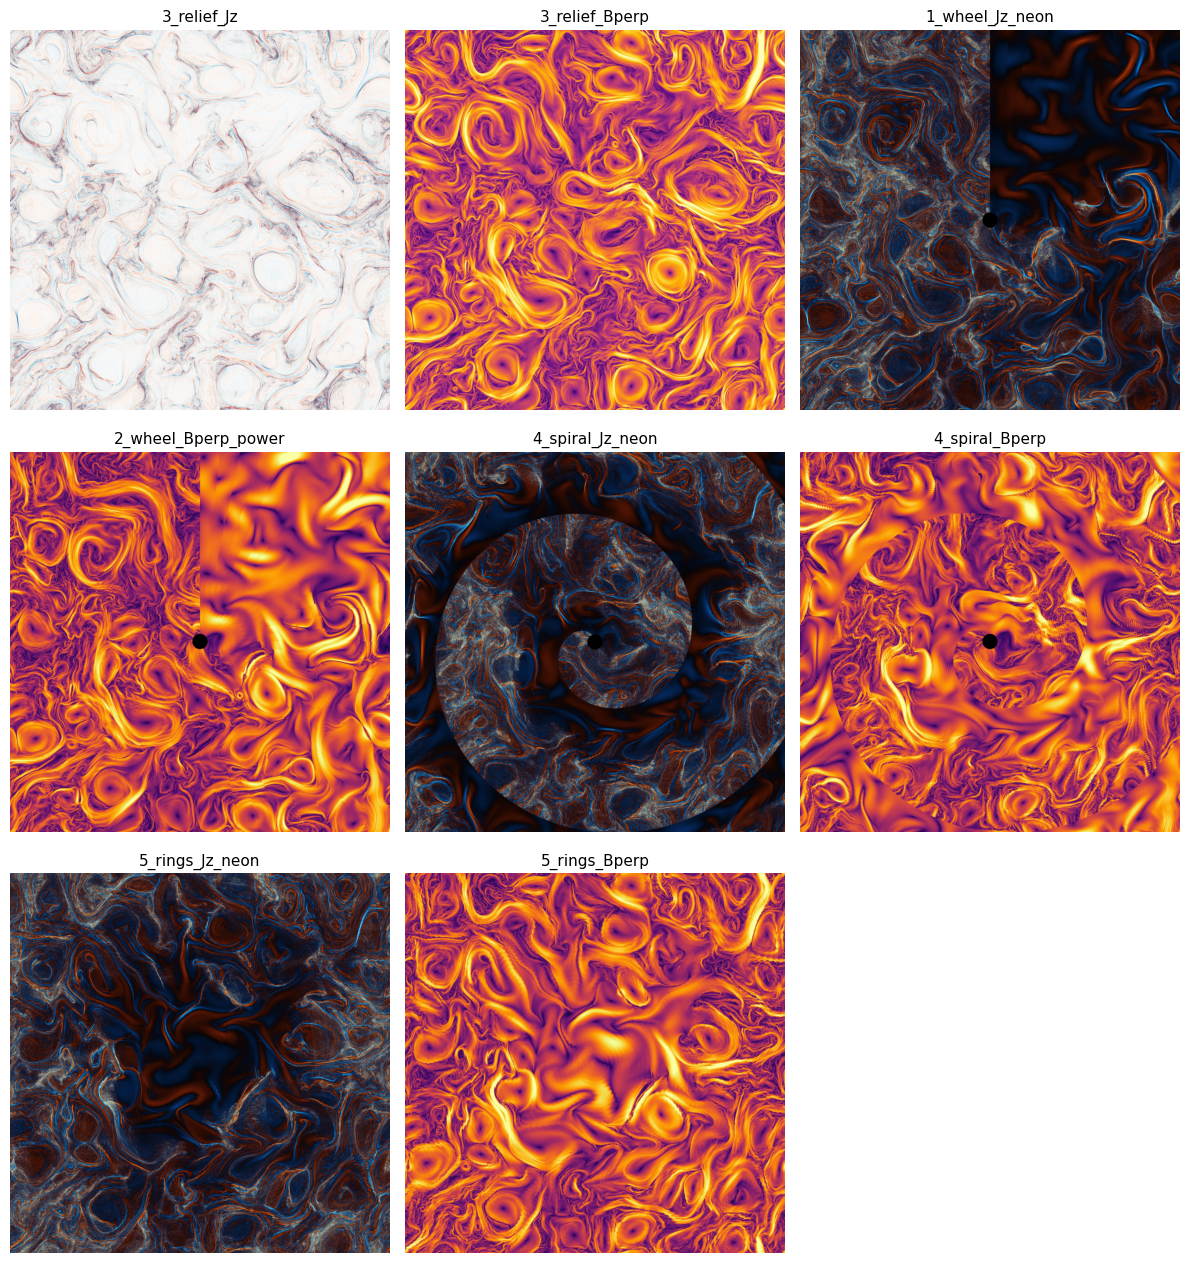

In [8]:
"""
Image gallery for the DiRAC competition: ideas 1-5 in one go.

One pass over the output times builds every time-based picture at once
(wedges, spiral, rings, each for |B_perp| and J_z); one snapshot (T_SINGLE)
gives the relief images and the colour-scaling comparison.

  1  wheel_Jz_neon         wedges, J_z on a dark "neon" diverging map
  2  wheel_Bperp_power     wedges, |B_perp| with power-law (gamma) scaling
     scaling_comparison    linear vs gamma scaling at T_SINGLE (for choosing)
  3  relief_Jz, relief_Bperp   hillshaded "landscape" at T_SINGLE
  4  spiral_Jz_neon, spiral_Bperp   wedges twisted into spiral arms
  5  rings_Jz_neon, rings_Bperp     time runs outwards like tree rings
     overview.png          thumbnails of everything, labelled

Set T_STEP = 5 for a quick preview (60 times), then T_STEP = 1 for the final images.
"""
import glob
import os
import re
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource, LinearSegmentedColormap, Normalize, PowerNorm, TwoSlopeNorm
from PIL import Image

# ------------------------------------------------------------------ settings
RUN = "/home/UNN/w24021992/NAS/DATA/Brms_0.24/beta_p_0.0625/beta_e_1/"
OUT_DIR = "gallery_bp0.0625"
dx = 0.0625                       # cell size [d_p]

T_FIRST, T_LAST = 1, 300          # time range for the wheels
T_STEP = 5                        # 5 = quick preview (60 wedges); 1 = all 300
T_SINGLE = 200                    # snapshot for relief + scaling comparison

TWIST = 1.5                       # spiral: turns of twist from centre to edge
R_INNER = 0.04                    # empty hub for wedges/spiral (fraction of half-width)
GAMMA_B = 0.5                     # power-law scaling for |B_perp| (1 = linear)
GAMMA_J = 0.6                     # power-law scaling for J_z (1 = linear)
CLIP_PCT = 99.5                   # colour range = this percentile
VERT_EXAG = 3.0                   # relief strength (larger = deeper ridges)
OUT_PX = 3000                     # final image size (10 in at 300 dpi)

NEON = LinearSegmentedColormap.from_list(
    "neon", ["#b8f6ff", "#00a8ff", "#08306b", "#000000", "#6b1d08", "#ff6a00", "#ffe39a"])
# ------------------------------------------------------------------------------


def deriv(f, d, axis):
    n = f.shape[axis]
    k = 2 * np.pi * np.fft.fftfreq(n, d=d)
    shape = [1] * f.ndim
    shape[axis] = n
    return np.real(np.fft.ifft(1j * k.reshape(shape) * np.fft.fft(f, axis=axis), axis=axis))


def read(tag, t):
    with h5py.File(f"{RUN}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T.astype(np.float64)


def fields(t, transpose):
    bx, by = read("Bx", t), read("By", t)
    if transpose:
        bx, by = bx.T, by.T
    jz = deriv(by, dx, 1) - deriv(bx, dx, 0)       # x along columns, y along rows
    return np.hypot(bx, by), jz


def times_available():
    out = []
    for fn in glob.glob(f"{RUN}Bx_ApJ_t*.h5"):
        m = re.search(r"_t(\d+)\.h5$", fn)
        if m:
            t = int(m.group(1))
            if T_FIRST <= t <= T_LAST and (t - T_FIRST) % T_STEP == 0 and os.path.exists(f"{RUN}By_ApJ_t{t}.h5"):
                out.append(t)
    return sorted(out)


def signed_power(j, vmax, gamma):
    return np.sign(j) * np.clip(np.abs(j) / vmax, 0, 1) ** gamma   # in [-1, 1]


def save(rgb, name, saved):
    """rgb: float array (ny, nx, 3) in [0,1], row 0 = bottom. Saves PNG (JPEG if > 20 MB)."""
    img = Image.fromarray((np.clip(rgb[::-1], 0, 1) * 255).astype(np.uint8), "RGB")
    if OUT_PX and img.width != OUT_PX:
        img = img.resize((OUT_PX, round(OUT_PX * img.height / img.width)), Image.LANCZOS)
    path = os.path.join(OUT_DIR, name + ".png")
    img.save(path, dpi=(300, 300))
    if os.path.getsize(path) > 20e6:
        os.remove(path)
        path = os.path.join(OUT_DIR, name + ".jpg")
        img.save(path, quality=95, dpi=(300, 300))
    saved.append((name, path))
    print(f"  saved {path}")


def colour_B(v, vmax):
    return plt.get_cmap("inferno")(PowerNorm(GAMMA_B, 0, vmax)(np.nan_to_num(v)))[..., :3]


def colour_J(v, vmax):
    return NEON(Normalize(-1, 1)(signed_power(np.nan_to_num(v), vmax, GAMMA_J)))[..., :3]


def groups_for(index_map, nt):
    flat = index_map.ravel()
    order = np.argsort(flat, kind="stable").astype(np.int64)
    start = np.searchsorted(flat[order], 0)
    counts = np.bincount(flat[flat >= 0], minlength=nt)
    return np.split(order[start:], np.cumsum(counts)[:-1])


def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    t0 = time.time()
    saved = []

    # ---------------- orientation from the single snapshot
    bx, by = read("Bx", T_SINGLE), read("By", T_SINGLE)
    div_a = np.std(deriv(bx, dx, 0) + deriv(by, dx, 1))
    div_b = np.std(deriv(bx, dx, 1) + deriv(by, dx, 0))
    transpose = div_a < div_b
    del bx, by
    print(f"x along {'rows -> transposing' if transpose else 'columns'}")

    # ---------------- single snapshot: scaling comparison (2) and relief (3)
    bperp, jz = fields(T_SINGLE, transpose)
    vb = np.percentile(bperp, CLIP_PCT)
    vj = np.percentile(np.abs(jz), CLIP_PCT)
    print(f"t={T_SINGLE}: |B_perp| {CLIP_PCT}th pct = {vb:.3g}, |J_z| {CLIP_PCT}th pct = {vj:.3g}")

    s = slice(None, None, 2)
    fig, axs = plt.subplots(2, 2, figsize=(12, 12))
    axs[0, 0].imshow(bperp[s, s], origin="lower", cmap="inferno", vmin=0, vmax=vb)
    axs[0, 0].set_title(r"$|B_\perp|$ linear")
    axs[0, 1].imshow(colour_B(bperp[s, s], vb), origin="lower")
    axs[0, 1].set_title(rf"$|B_\perp|$ power law, $\gamma$ = {GAMMA_B}")
    axs[1, 0].imshow(jz[s, s], origin="lower", cmap=NEON, vmin=-vj, vmax=vj)
    axs[1, 0].set_title(r"$J_z$ linear")
    axs[1, 1].imshow(colour_J(jz[s, s], vj), origin="lower")
    axs[1, 1].set_title(rf"$J_z$ signed power, $\gamma$ = {GAMMA_J}")
    for ax in axs.flat:
        ax.axis("off")
    fig.tight_layout()
    path = os.path.join(OUT_DIR, "scaling_comparison.png")
    fig.savefig(path, dpi=120)
    plt.close(fig)
    print(f"  saved {path}")

    ls = LightSource(azdeg=315, altdeg=35)
    jn = np.clip(jz / vj, -1, 1)
    rgb = ls.shade(jn, cmap=plt.get_cmap("RdBu_r"), norm=TwoSlopeNorm(0, -1, 1),
                   blend_mode="soft", vert_exag=VERT_EXAG)[..., :3]
    save(rgb, "3_relief_Jz", saved)
    bn = np.clip(bperp / vb, 0, 1)
    rgb = ls.shade(bn, cmap=plt.get_cmap("inferno"), norm=PowerNorm(GAMMA_B, 0, 1),
                   blend_mode="soft", vert_exag=VERT_EXAG)[..., :3]
    save(rgb, "3_relief_Bperp", saved)
    del bperp, jz, jn, bn, rgb

    # ---------------- geometry of the time pictures (whole square box)
    times = times_available()
    nt = len(times)
    if nt == 0:
        raise SystemExit("no Bx/By files found for the wheels")
    n = read("Bx", times[0]).shape[0]
    r = n // 2
    Y, X = np.mgrid[0:n, 0:n] + 0.5 - r
    rad = np.hypot(X, Y)
    theta = np.mod(np.arctan2(X, Y), 2 * np.pi)              # clockwise from 12 o'clock
    hub = rad < R_INNER * r
    wedge = np.minimum((theta / (2 * np.pi) * nt).astype(np.int32), nt - 1)
    spiral = np.minimum((np.mod(theta + 2 * np.pi * TWIST * rad / r, 2 * np.pi)
                         / (2 * np.pi) * nt).astype(np.int32), nt - 1)
    rings = np.minimum((rad / (r * np.sqrt(2)) * nt).astype(np.int32), nt - 1)
    wedge[hub] = -1
    spiral[hub] = -1
    maps = {"wheel": wedge, "spiral": spiral, "rings": rings}
    groups = {k: groups_for(v, nt) for k, v in maps.items()}
    del X, Y, rad, theta, wedge, spiral, rings
    values = {(g, q): np.full(n * n, np.nan, dtype=np.float32) for g in maps for q in ("B", "J")}

    print(f"{nt} times (t = {times[0]} .. {times[-1]}, step {T_STEP}); reading ...")
    for k, t in enumerate(times):
        bperp, jz = fields(t, transpose)
        bperp, jz = bperp.ravel(), jz.ravel()
        for g in maps:
            idx = groups[g][k]
            values[(g, "B")][idx] = bperp[idx]
            values[(g, "J")][idx] = jz[idx]
        if k % 10 == 0 or k == nt - 1:
            el = time.time() - t0
            print(f"  t={t:4d} ({k + 1}/{nt})  {el:5.0f} s, ~{el / (k + 1) * (nt - k - 1):5.0f} s to go", flush=True)

    # ---------------- render the time pictures (1, 2, 4, 5)
    names = {("wheel", "J"): "1_wheel_Jz_neon", ("wheel", "B"): "2_wheel_Bperp_power",
             ("spiral", "J"): "4_spiral_Jz_neon", ("spiral", "B"): "4_spiral_Bperp",
             ("rings", "J"): "5_rings_Jz_neon", ("rings", "B"): "5_rings_Bperp"}
    for (g, q), name in names.items():
        v = values[(g, q)].reshape(n, n)
        if q == "B":
            rgb = colour_B(v, np.nanpercentile(v, CLIP_PCT))
        else:
            rgb = colour_J(v, np.nanpercentile(np.abs(v), CLIP_PCT))
        rgb[np.isnan(v)] = 0.0                                  # hub -> black
        save(rgb, name, saved)

    # ---------------- overview sheet
    cols = 3
    rows = int(np.ceil(len(saved) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 4.3 * rows))
    for ax in np.ravel(axs):
        ax.axis("off")
    for ax, (name, path) in zip(np.ravel(axs), saved):
        im = Image.open(path)
        im.thumbnail((800, 800))
        ax.imshow(im)
        ax.set_title(name, fontsize=11)
    fig.tight_layout()
    path = os.path.join(OUT_DIR, "overview.png")
    fig.savefig(path, dpi=110)
    print(f"  saved {path}\ndone in {time.time() - t0:.0f} s")


if __name__ == "__main__":
    main()